# Cybersecurity Analytics & Intrusion Detection Dashboard
## Notebook 2b — Robustesse : leakage et raccourcis

Les scores de CICIDS2017 sont souvent « trop beaux ». Ce notebook teste deux risques, avec **le même modèle (XGBoost) et les mêmes hyperparamètres** :

| Scénario | Split | Features | Question posée |
|---|---|---|---|
| **A — Aléatoire** | stratifié 80/20 | toutes | Score « optimiste » classique |
| **B — Temporel par blocs** | 80 % début / tampon / fin | toutes | Protocole de référence du projet (Notebook 2) |
| **C — Temporel, sans `Destination Port`** | idem B | toutes sauf le port | Le modèle triche-t-il avec le port ? |

**Lecture :**
- **A − B** grand → un split aléatoire gonfle les scores (leakage entre flux voisins).
- **B − C** grand → le modèle s'appuie fortement sur le port de destination (raccourci qui se généralise mal : un attaquant peut changer de port).

> Ce notebook **remplace** l'ancienne vérification par « fingerprint arrondi + GroupShuffleSplit » : avec 2,2 M de groupes pour 2,5 M de lignes (ratio 1,13), les groupes étaient quasi tous de taille 1, donc ce split était presque équivalent à un split aléatoire et ne prouvait rien.

## 1. Imports et configuration

In [1]:
import os

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import xgboost as xgb
from sklearn.metrics import (
    accuracy_score, matthews_corrcoef, precision_recall_fscore_support,
)
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder

pd.set_option("display.max_columns", 100)

SEED = 42
MIN_SAMPLES = 50
TRAIN_FRAC = 0.80
GAP_FRAC = 0.01
FAST_MODE = False   # True = train réduit à 20 % (test rapide)

PROCESSED_CSV = "../data/processed/cleaned_network_traffic.csv"
RESULTS_DIR = "../results/"
IMAGES_DIR = "../images/"
for d in (RESULTS_DIR, IMAGES_DIR):
    os.makedirs(d, exist_ok=True)

XGB_PARAMS = dict(n_estimators=100, max_depth=6, learning_rate=0.2, subsample=0.7)
print("Configuration OK.")

Configuration OK.


## 2. Données (mêmes filtres que le Notebook 2)

In [2]:
df = pd.read_csv(PROCESSED_CSV, low_memory=False)

META_COLS = ["Label", "Attack_Category", "Is_Attack", "Source_File", "Day", "Row_Order"]
ALL_FEATURES = [c for c in df.columns if c not in META_COLS]
df[ALL_FEATURES] = df[ALL_FEATURES].astype("float32")

class_counts = df["Attack_Category"].value_counts()
rare_classes = class_counts[class_counts < MIN_SAMPLES].index.tolist()
df_ml = df[~df["Attack_Category"].isin(rare_classes)].copy()

le = LabelEncoder()
y = pd.Series(le.fit_transform(df_ml["Attack_Category"]), index=df_ml.index)
CLASSES = list(le.classes_)

print("Classes exclues :", rare_classes)
print("Shape :", df_ml.shape, "| Features :", len(ALL_FEATURES))

Classes exclues : ['Infiltration', 'Heartbleed']
Shape : (2520751, 85) | Features : 79


## 3. Les trois splits

In [3]:
def blocked_temporal_split(data, train_frac=0.80, gap_frac=0.01):
    d = data[["Source_File", "Label", "Row_Order"]].sort_values(["Source_File", "Label", "Row_Order"])
    grp = d.groupby(["Source_File", "Label"], sort=False)
    frac = grp.cumcount() / grp["Row_Order"].transform("size")
    return d.index[frac < train_frac], d.index[frac >= train_frac + gap_frac]


# A : aléatoire stratifié
idx_A_train, idx_A_test = train_test_split(
    df_ml.index, test_size=0.2, stratify=y, random_state=SEED
)
# B et C : temporel par blocs
idx_B_train, idx_B_test = blocked_temporal_split(df_ml, TRAIN_FRAC, GAP_FRAC)

FEATURES_NO_PORT = [c for c in ALL_FEATURES if c != "Destination Port"]

scenarios = {
    "A - Aléatoire (toutes features)":        (idx_A_train, idx_A_test, ALL_FEATURES),
    "B - Temporel (toutes features)":         (idx_B_train, idx_B_test, ALL_FEATURES),
    "C - Temporel (sans Destination Port)":   (idx_B_train, idx_B_test, FEATURES_NO_PORT),
}
for name, (tr, te, feats) in scenarios.items():
    print(f"{name:<40} train={len(tr):>9,}  test={len(te):>8,}  features={len(feats)}")

A - Aléatoire (toutes features)          train=2,016,600  test= 504,151  features=79
B - Temporel (toutes features)           train=2,016,609  test= 478,932  features=79
C - Temporel (sans Destination Port)     train=2,016,609  test= 478,932  features=78


## 4. Entraînement et évaluation

In [4]:
summary_rows, recall_rows = [], []

for name, (tr, te, feats) in scenarios.items():
    tr_used = tr
    if FAST_MODE:
        tr_used = pd.Index(np.random.RandomState(SEED).choice(tr, size=int(len(tr) * 0.2), replace=False))

    X_tr, y_tr = df_ml.loc[tr_used, feats], y.loc[tr_used].values
    X_te, y_te = df_ml.loc[te, feats], y.loc[te].values

    model = xgb.XGBClassifier(**XGB_PARAMS, tree_method="hist", eval_metric="mlogloss",
                              random_state=SEED, n_jobs=-1)
    model.fit(X_tr, y_tr)
    y_pred = model.predict(X_te)

    labels = list(range(len(CLASSES)))
    _, rec, f1, _ = precision_recall_fscore_support(y_te, y_pred, labels=labels, zero_division=0)
    _, _, f1w, _ = precision_recall_fscore_support(y_te, y_pred, average="weighted", zero_division=0)

    summary_rows.append({
        "Scenario": name,
        "Accuracy": round(accuracy_score(y_te, y_pred), 4),
        "F1_weighted": round(f1w, 4),
        "Macro_F1": round(float(np.mean(f1)), 4),
        "MCC": round(matthews_corrcoef(y_te, y_pred), 4),
    })
    for c, r in zip(CLASSES, rec):
        recall_rows.append({"Scenario": name, "Class": c, "Recall": round(float(r), 4)})
    print(f"{name:<40} Macro F1 = {summary_rows[-1]['Macro_F1']:.4f}")

robust_df = pd.DataFrame(summary_rows)
recall_df = pd.DataFrame(recall_rows)
robust_df

A - Aléatoire (toutes features)          Macro F1 = 0.9722
B - Temporel (toutes features)           Macro F1 = 0.8413
C - Temporel (sans Destination Port)     Macro F1 = 0.8303


,Scenario,Accuracy,F1_weighted,Macro_F1,MCC
0,A - Aléatoire (toutes features),0.9992,0.9992,0.9722,0.9972
1,B - Temporel (toutes features),0.9955,0.9952,0.8413,0.9850
2,C - Temporel (sans Destination Port),0.9944,0.9940,0.8303,0.9812


In [5]:
recall_pivot = recall_df.pivot(index="Class", columns="Scenario", values="Recall")[list(scenarios)]
recall_pivot

Scenario,A - Aléatoire (toutes features),B - Temporel (toutes features),C - Temporel (sans Destination Port)
Class,,,
Benign,0.9993,0.9998,0.9994
Bot,0.7429,0.0054,0.0000
Brute Force,0.9984,0.9977,0.9758
DDoS,1.0000,0.9980,0.9977
DoS,0.9996,0.9577,0.9478
Port Scan,0.9994,0.9959,0.9959
Web Attack,0.9883,0.9728,0.9654


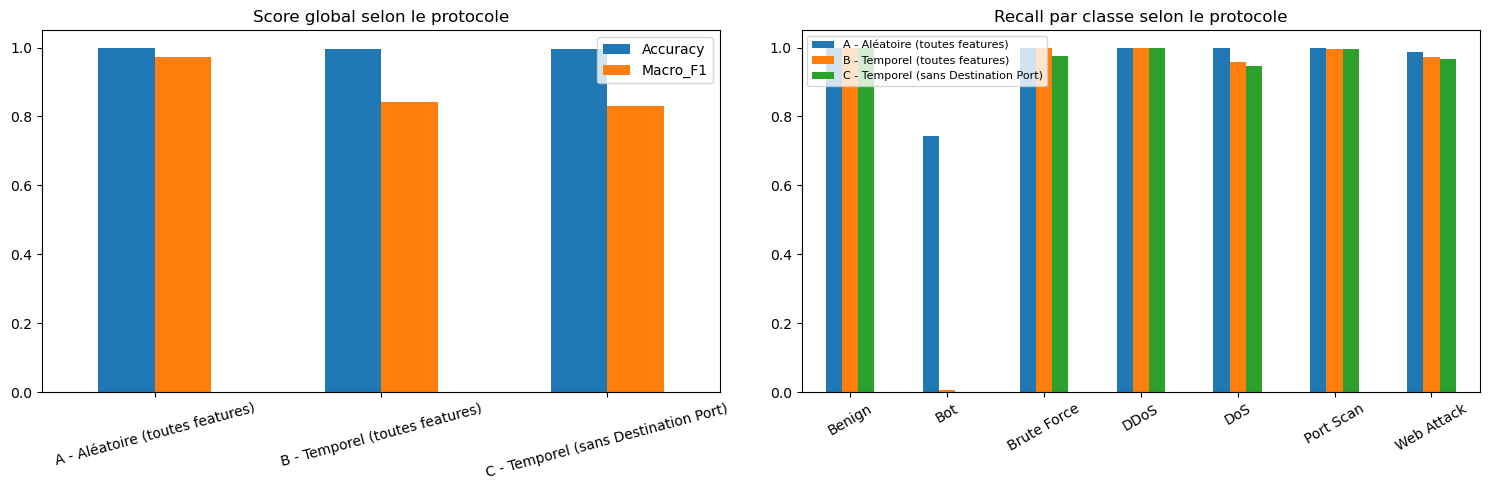

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

robust_df.set_index("Scenario")[["Accuracy", "Macro_F1"]].plot(kind="bar", ax=axes[0], rot=15)
axes[0].set_ylim(0, 1.05)
axes[0].set_title("Score global selon le protocole")
axes[0].set_xlabel("")

recall_pivot.plot(kind="bar", ax=axes[1], rot=30)
axes[1].set_ylim(0, 1.05)
axes[1].set_title("Recall par classe selon le protocole")
axes[1].set_xlabel("")
axes[1].legend(fontsize=8)

plt.tight_layout()
plt.savefig(IMAGES_DIR + "robustness_check.png", dpi=150)
plt.show()

## 5. Interprétation automatique

In [7]:
mf1 = robust_df.set_index("Scenario")["Macro_F1"]
gap_split = mf1.iloc[0] - mf1.iloc[1]    # A - B
gap_port = mf1.iloc[1] - mf1.iloc[2]     # B - C

def level(g):
    g = abs(g)
    return "faible (< 1 point)" if g < 0.01 else "modéré (1 à 5 points)" if g < 0.05 else "important (> 5 points)"

print(f"A - B (effet du type de split)       : {gap_split:+.4f}  -> {level(gap_split)}")
print(f"B - C (effet de Destination Port)    : {gap_port:+.4f}  -> {level(gap_port)}")

if gap_split < 0.01:
    print("\nLe split aléatoire ne gonfle pas notablement les scores : le dataset est réellement séparable pour ces catégories.")
else:
    print("\nLe split aléatoire gonfle les scores : utiliser le split temporel (B) comme référence dans le README.")

if gap_port >= 0.01:
    print("Le modèle dépend sensiblement du port de destination : le mentionner comme limite (un attaquant peut changer de port).")
else:
    print("Le modèle ne dépend pas fortement du port de destination.")

A - B (effet du type de split)       : +0.1309  -> important (> 5 points)
B - C (effet de Destination Port)    : +0.0110  -> modéré (1 à 5 points)

Le split aléatoire gonfle les scores : utiliser le split temporel (B) comme référence dans le README.
Le modèle dépend sensiblement du port de destination : le mentionner comme limite (un attaquant peut changer de port).


## 6. Export

In [8]:
robust_df.to_csv(RESULTS_DIR + "leakage_robustness_check.csv", index=False)
recall_df.to_csv(RESULTS_DIR + "leakage_per_class_recall.csv", index=False)
print("Exports OK.")

Exports OK.
